FoldNet freq=5: 100%|██████████| 8000/8000 [00:05<00:00, 1378.27it/s, loss=0.0000]


FoldNet freq=5: MSE=5.51e-06


MLP freq=5: 100%|██████████| 8000/8000 [00:03<00:00, 2375.09it/s, loss=0.0000]


MLP freq=5: MSE=1.11e-05


FoldNet freq=10: 100%|██████████| 8000/8000 [00:05<00:00, 1406.12it/s, loss=0.0000]


FoldNet freq=10: MSE=3.76e-05


... (14 outputs left out)

FoldNet freq=200: 100%|██████████| 8000/8000 [00:05<00:00, 1391.10it/s, loss=0.4876]


FoldNet freq=200: MSE=5.06e-01


MLP freq=200: 100%|██████████| 8000/8000 [00:03<00:00, 2421.15it/s, loss=0.4965]


MLP freq=200: MSE=4.99e-01


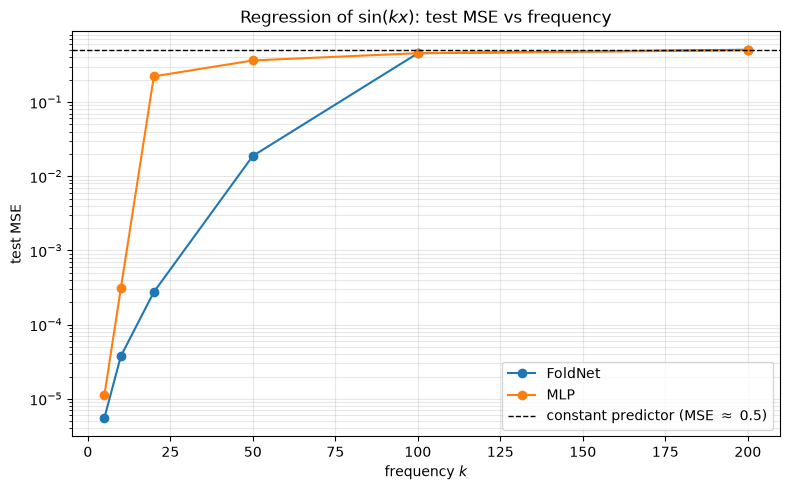

In [1]:
"""Test 4 — Regression of sin(freq * x): test MSE vs frequency."""
import os
import numpy as np
import torch, matplotlib.pyplot as plt
from foldnet_lib import FoldNet, MLP, n_params, match_mlp, train, DEV

RESULTS_DIR = "results"
FREQS = [5, 10, 20, 50, 100, 200]
STEPS = 8000
COLORS = {"FoldNet": "tab:blue", "MLP": "tab:orange"}


if __name__ == "__main__":
    os.makedirs(RESULTS_DIR, exist_ok=True)

    torch.manual_seed(0)
    x = torch.rand(2048, 1) * 2 - 1
    xt = torch.linspace(-1, 1, 8192).unsqueeze(1)

    results = {"FoldNet": [], "MLP": []}
    for freq in FREQS:
        y = torch.sin(freq * x)
        yt = torch.sin(freq * xt)
        for name in ["FoldNet", "MLP"]:
            torch.manual_seed(42)
            if name == "FoldNet":
                m = FoldNet(1, 1, d=32, depth=6, k=2)
            else:
                m = match_mlp(n_params(FoldNet(1, 1, d=32, depth=6, k=2)), 1, 1, 6)
            train(m, x, y, steps=STEPS, desc=f"{name} freq={freq}")
            with torch.no_grad():
                pred = m(xt.to(DEV)).cpu().numpy().ravel()
            mse = ((pred - yt.numpy().ravel()) ** 2).mean()
            results[name].append(mse)
            print(f"{name} freq={freq}: MSE={mse:.2e}")

    fig, ax = plt.subplots(figsize=(8, 5))
    for name in ["FoldNet", "MLP"]:
        ax.semilogy(FREQS, results[name], "o-", color=COLORS[name], label=name)
    ax.axhline(0.5, color="k", ls="--", lw=1, label="constant predictor (MSE $\\approx$ 0.5)")
    ax.set_xlabel("frequency $k$")
    ax.set_ylabel("test MSE")
    ax.set_title(r"Regression of $\sin(kx)$: test MSE vs frequency")
    ax.legend()
    ax.grid(alpha=0.3, which="both")
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "test4_sin_kx.png"), dpi=150)
    plt.show()